## Завдання 1. ER-діаграма: обраний домен

**Сценарій: Movie Recommendation**

**Бізнесові сутності:**
- `hw2_users`: користувачі сервісу (дата народження, стать, країна);
- `hw2_movies`: фільми каталогу (назва, дата релізу, жанр, країна);
- `hw2_ratings`: оцінки, які користувачі ставлять фільмам (`stars`, час оцінки `rated_at`).

**Зв'язок N:M.** Користувач оцінює багато фільмів, а фільм оцінюють багато користувачів. Тому `hw2_ratings` є bridge-таблицею з складеним первинним ключем `(user_id, movie_id)`: один користувач має не більше однієї оцінки на фільм.

**ML-задача.** Прогнозуємо відтік (churn): чи не поставить користувач жодної оцінки протягом наступних 30 днів. Це допомагає вчасно запропонувати персональну добірку або нагадування активним користувачам, які «затихають». Ознаки користувача (`ratings_count_30d`, `avg_rating_30d`, `days_since_last_rating`) обчислюються лише з оцінок, відомих на момент `prediction_ts`.

ER Diagram

![Movie Rating.png](<attachment:Movie Rating.png>)
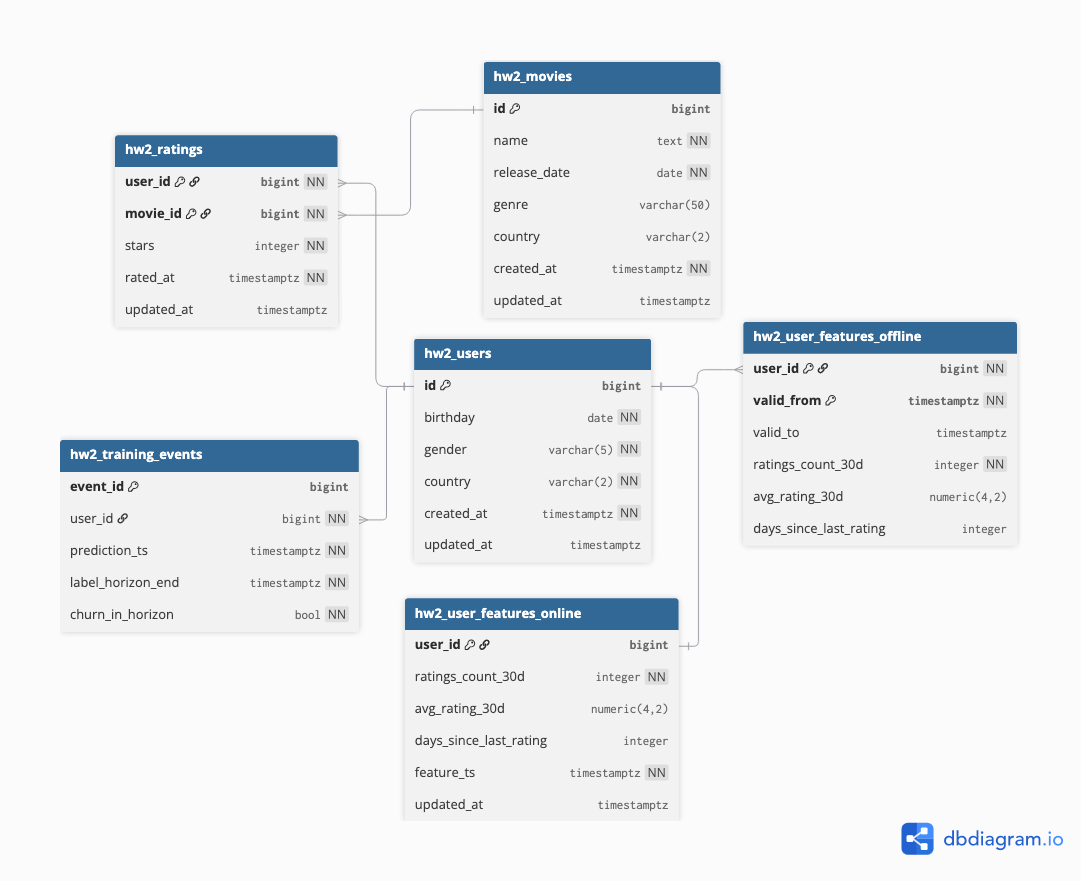

### Кардинальності та обов'язковість зв'язків

| Зв'язок | Кардинальність | Обов'язковість |
|---|---|---|
| `hw2_users` → `hw2_ratings` | 1 : 0..N | Користувач може не мати оцінок; оцінка без користувача неможлива (`user_id NOT NULL`) |
| `hw2_movies` → `hw2_ratings` | 1 : 0..N | Фільм може не мати оцінок; оцінка без фільму неможлива (`movie_id NOT NULL`) |
| `hw2_users` ↔ `hw2_movies` | N : M через `hw2_ratings` | Bridge-таблиця зі складеним PK `(user_id, movie_id)` |
| `hw2_users` → `hw2_user_features_offline` | 1 : 0..N | Користувач може мати багато версій ознак; версія без користувача неможлива |
| `hw2_users` → `hw2_training_events` | 1 : 0..N | Користувач може мати багато подій; подія без користувача неможлива |
| `hw2_users` → `hw2_user_features_online` | 1 : 0..1 | Не більше одного поточного рядка; `user_id` є одночасно PK і FK |

Рівні: business (`hw2_users`, `hw2_movies`, `hw2_ratings`), offline (`hw2_user_features_offline`, `hw2_training_events`), online (`hw2_user_features_online`).

## Setup

In [35]:
try:
    import pgserver, sqlalchemy, psycopg2, sql  # already installed
except ImportError:
    %pip install -q pgserver jupysql psycopg2-binary sqlalchemy

In [36]:
import pgserver, tempfile
from sqlalchemy import create_engine

pg_dir = tempfile.mkdtemp()
db = pgserver.get_server(pg_dir)
engine = create_engine(
    db.get_uri().replace("postgresql://", "postgresql+psycopg2://", 1)
)

%load_ext sql
%config SqlMagic.displaylimit = 100
%sql engine

The sql extension is already loaded. To reload it, use:
  %reload_ext sql


## Завдання 2. DDL у PostgreSQL

In [37]:
%%sql
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_user_features_online,
    hw2_training_events,
    hw2_user_features_offline,
    hw2_ratings,
    hw2_movies,
    hw2_users
CASCADE;

CREATE TABLE hw2_users (
    id         BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    birthday   DATE NOT NULL,
    gender     VARCHAR(5) NOT NULL CHECK (gender IN ('M', 'F', 'other')),
    country    VARCHAR(2) NOT NULL,
    created_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP,
    updated_at TIMESTAMPTZ
);

CREATE TABLE hw2_movies (
    id           BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    name         TEXT NOT NULL,
    release_date DATE NOT NULL,
    genre        VARCHAR(50),
    country      VARCHAR(2),
    created_at   TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP,
    updated_at   TIMESTAMPTZ
);

CREATE TABLE hw2_ratings (
    user_id    BIGINT NOT NULL REFERENCES hw2_users(id),
    movie_id   BIGINT NOT NULL REFERENCES hw2_movies(id),
    stars      INTEGER NOT NULL CHECK (stars >= 0 AND stars <= 10),
    rated_at   TIMESTAMPTZ NOT NULL,
    updated_at TIMESTAMPTZ,

    PRIMARY KEY (user_id, movie_id)
);

CREATE TABLE hw2_user_features_offline (
    user_id                BIGINT NOT NULL REFERENCES hw2_users(id),
    valid_from             TIMESTAMPTZ NOT NULL,
    valid_to               TIMESTAMPTZ,
    ratings_count_30d      INTEGER NOT NULL CHECK (ratings_count_30d >= 0),
    avg_rating_30d         NUMERIC(4, 2) CHECK (avg_rating_30d IS NULL OR (avg_rating_30d >= 0 AND avg_rating_30d <= 10)),
    days_since_last_rating INTEGER CHECK (days_since_last_rating IS NULL OR days_since_last_rating >= 0),

    PRIMARY KEY (user_id, valid_from),

    CHECK (valid_to IS NULL OR valid_to > valid_from)
);

CREATE INDEX hw2_idx_user_features_asof
    ON hw2_user_features_offline (user_id, valid_from DESC);

CREATE TABLE hw2_training_events (
    event_id          BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    user_id           BIGINT NOT NULL REFERENCES hw2_users(id),
    prediction_ts     TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    churn_in_horizon  BOOLEAN NOT NULL,

    CHECK (label_horizon_end > prediction_ts)
);

CREATE TABLE hw2_user_features_online (
    user_id                BIGINT PRIMARY KEY REFERENCES hw2_users(id),
    ratings_count_30d      INTEGER NOT NULL CHECK (ratings_count_30d >= 0),
    avg_rating_30d         NUMERIC(4, 2) CHECK (avg_rating_30d IS NULL OR (avg_rating_30d >= 0 AND avg_rating_30d <= 10)),
    days_since_last_rating INTEGER CHECK (days_since_last_rating IS NULL OR days_since_last_rating >= 0),
    feature_ts             TIMESTAMPTZ NOT NULL,
    updated_at             TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP
);

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

++
||
++
++

In [38]:
%%sql
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'public' AND table_name LIKE 'hw2_%'
ORDER BY table_name;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

6 rows affected.

table_name
hw2_movies
hw2_ratings
hw2_training_events
hw2_user_features_offline
hw2_user_features_online
hw2_users


## Завдання 3. Нормалізація

**3НФ.** Таблиці `hw2_users`, `hw2_movies` та `hw2_ratings` перебувають у 3НФ: кожен неключовий атрибут залежить від ключа, від усього ключа і лише від нього. Атрибути користувача й фільму не повторюються в `hw2_ratings`, а лише посилаються на них через FK, тому немає аномалій оновлення.

**Функціональні залежності:**
- `user_id → birthday, gender, country`
- `movie_id → name, release_date, genre, country`
- `(user_id, movie_id) → stars, rated_at`
- `(user_id, valid_from) → valid_to, ratings_count_30d, avg_rating_30d, days_since_last_rating`
- `event_id → user_id, prediction_ts, label_horizon_end, churn_in_horizon`

Вік не зберігається, бо він похідний від `birthday`. Спрощення: у фільму одне значення `genre`; для кількох жанрів потрібні `genres` і bridge `movie_genres`.

**Денормалізація.** Навмисно денормалізована `hw2_user_features_online`: вона зберігає попередньо обчислені агрегати з `hw2_ratings`, тобто дублює інформацію. Це виправдано read pattern: lookup за `user_id` (PK), низька latency та жодних JOIN чи агрегацій під час запиту.

**Ризик.** Дублювання може призвести до неузгодженості: online-рядок застаріє відносно offline-версії або нових оцінок. Свіжість контролюють `feature_ts` та `updated_at`.

**Оновлення.** Періодично беремо поточну версію з offline (`valid_to IS NULL`) і записуємо в online через `INSERT ... ON CONFLICT (user_id) DO UPDATE`, виставляючи `feature_ts` та `updated_at`.

## Завдання 4. Point-in-Time correctness

Три користувачі з різною поведінкою:
- **користувач 1**: активний у серпні, після 20 серпня «затихає» (5 версій ознак);
- **користувач 2**: стабільно активний (3 версії);
- **користувач 3**: новий, з рідкою активністю (3 версії).

Ознаки в `hw2_user_features_offline` обчислені зі знімка оцінок на момент `valid_from`: вікно 30 днів до цього моменту, а `days_since_last_rating` рахується від останньої оцінки за весь час. Версії кожного користувача йдуть підряд: `valid_to` попередньої версії дорівнює `valid_from` наступної. Інтервали напіввідкриті: `[valid_from, valid_to)`.

In [39]:
%%sql
INSERT INTO hw2_users (id, birthday, gender, country) VALUES
    (1, DATE '1990-05-14', 'F',     'UA'),
    (2, DATE '1985-09-02', 'M',     'PL'),
    (3, DATE '2000-01-23', 'other', 'UA');

INSERT INTO hw2_movies (id, name, release_date, genre, country) VALUES
    (1, 'Inception',     DATE '2010-07-16', 'Sci-Fi',   'US'),
    (2, 'The Godfather', DATE '1972-03-24', 'Crime',    'US'),
    (3, 'Amelie',        DATE '2001-04-25', 'Romance',  'FR'),
    (4, 'Parasite',      DATE '2019-05-30', 'Thriller', 'KR'),
    (5, 'Spirited Away', DATE '2001-07-20', 'Anime',    'JP'),
    (6, 'The Matrix',    DATE '1999-03-31', 'Sci-Fi',   'US'),
    (7, 'Pulp Fiction',  DATE '1994-10-14', 'Crime',    'US'),
    (8, 'Shadows of Forgotten Ancestors', DATE '1965-09-04', 'Drama', 'UA');

INSERT INTO hw2_ratings (user_id, movie_id, stars, rated_at) VALUES
    -- user 1: active in July-August, silent after 2026-08-20
    (1, 1, 10, TIMESTAMPTZ '2026-07-22 14:00:00+00'),
    (1, 2,  8, TIMESTAMPTZ '2026-07-29 14:00:00+00'),
    (1, 3,  8, TIMESTAMPTZ '2026-08-08 14:00:00+00'),
    (1, 4,  6, TIMESTAMPTZ '2026-08-20 14:00:00+00'),
    -- user 2: steady activity
    (2, 1,  8, TIMESTAMPTZ '2026-07-24 14:00:00+00'),
    (2, 5, 10, TIMESTAMPTZ '2026-07-31 14:00:00+00'),
    (2, 6,  8, TIMESTAMPTZ '2026-08-13 14:00:00+00'),
    (2, 2, 10, TIMESTAMPTZ '2026-08-26 14:00:00+00'),
    (2, 7,  8, TIMESTAMPTZ '2026-09-07 14:00:00+00'),
    (2, 3, 10, TIMESTAMPTZ '2026-09-21 14:00:00+00'),
    -- user 3: new user, rare activity
    (3, 4,  6, TIMESTAMPTZ '2026-08-30 14:00:00+00'),
    (3, 8,  4, TIMESTAMPTZ '2026-09-17 14:00:00+00');

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

3 rows affected.

8 rows affected.

12 rows affected.

++
||
++
++

In [40]:
%%sql
INSERT INTO hw2_user_features_offline
    (user_id, valid_from, valid_to, ratings_count_30d, avg_rating_30d, days_since_last_rating)
VALUES
    -- user 1: 5 consecutive versions
    (1, TIMESTAMPTZ '2026-07-20 00:00:00+00', TIMESTAMPTZ '2026-08-03 00:00:00+00', 0, NULL, NULL),
    (1, TIMESTAMPTZ '2026-08-03 00:00:00+00', TIMESTAMPTZ '2026-08-19 00:00:00+00', 2, 9.00,  4),
    (1, TIMESTAMPTZ '2026-08-19 00:00:00+00', TIMESTAMPTZ '2026-09-02 00:00:00+00', 3, 8.67, 10),
    (1, TIMESTAMPTZ '2026-09-02 00:00:00+00', TIMESTAMPTZ '2026-09-23 00:00:00+00', 2, 7.00, 12),
    (1, TIMESTAMPTZ '2026-09-23 00:00:00+00', NULL,                                  0, NULL, 33),
    -- user 2: 3 versions
    (2, TIMESTAMPTZ '2026-08-19 00:00:00+00', TIMESTAMPTZ '2026-09-02 00:00:00+00', 3, 8.67,  5),
    (2, TIMESTAMPTZ '2026-09-02 00:00:00+00', TIMESTAMPTZ '2026-09-23 00:00:00+00', 2, 9.00,  6),
    (2, TIMESTAMPTZ '2026-09-23 00:00:00+00', NULL,                                  3, 9.33,  1),
    -- user 3: 3 versions
    (3, TIMESTAMPTZ '2026-08-28 00:00:00+00', TIMESTAMPTZ '2026-09-07 00:00:00+00', 0, NULL, NULL),
    (3, TIMESTAMPTZ '2026-09-07 00:00:00+00', TIMESTAMPTZ '2026-09-23 00:00:00+00', 1, 6.00,  7),
    (3, TIMESTAMPTZ '2026-09-23 00:00:00+00', NULL,                                  2, 5.00,  5);

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

11 rows affected.

++
||
++
++

In [41]:
%%sql
INSERT INTO hw2_training_events
    (user_id, prediction_ts, label_horizon_end, churn_in_horizon)
VALUES
    (1, TIMESTAMPTZ '2026-08-08 10:00:00+00', TIMESTAMPTZ '2026-09-07 10:00:00+00', FALSE),
    -- exactly on the boundary between two versions: must get the version starting at 2026-08-19
    (1, TIMESTAMPTZ '2026-08-19 00:00:00+00', TIMESTAMPTZ '2026-09-18 00:00:00+00', FALSE),
    (1, TIMESTAMPTZ '2026-08-28 10:00:00+00', TIMESTAMPTZ '2026-09-27 10:00:00+00', TRUE),
    (1, TIMESTAMPTZ '2026-09-07 10:00:00+00', TIMESTAMPTZ '2026-10-07 10:00:00+00', TRUE),
    (2, TIMESTAMPTZ '2026-08-23 10:00:00+00', TIMESTAMPTZ '2026-09-22 10:00:00+00', FALSE),
    (2, TIMESTAMPTZ '2026-09-05 10:00:00+00', TIMESTAMPTZ '2026-10-05 10:00:00+00', FALSE),
    (3, TIMESTAMPTZ '2026-09-02 10:00:00+00', TIMESTAMPTZ '2026-10-02 10:00:00+00', FALSE),
    (3, TIMESTAMPTZ '2026-09-12 10:00:00+00', TIMESTAMPTZ '2026-10-12 10:00:00+00', FALSE);

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

8 rows affected.

++
||
++
++

### Online-рівень: оновлення з offline

Поточна версія (`valid_to IS NULL`) копіюється в online через upsert, як описано в Завданні 3.

In [42]:
%%sql
INSERT INTO hw2_user_features_online
    (user_id, ratings_count_30d, avg_rating_30d,
     days_since_last_rating, feature_ts)
SELECT user_id, ratings_count_30d, avg_rating_30d,
       days_since_last_rating, valid_from
FROM hw2_user_features_offline
WHERE valid_to IS NULL
ON CONFLICT (user_id) DO UPDATE SET
    ratings_count_30d      = EXCLUDED.ratings_count_30d,
    avg_rating_30d         = EXCLUDED.avg_rating_30d,
    days_since_last_rating = EXCLUDED.days_since_last_rating,
    feature_ts             = EXCLUDED.feature_ts,
    updated_at             = CURRENT_TIMESTAMP;

SELECT * FROM hw2_user_features_online ORDER BY user_id;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

3 rows affected.

3 rows affected.

user_id,ratings_count_30d,avg_rating_30d,days_since_last_rating,feature_ts,updated_at
1,0,None,33,2026-09-23 00:00:00+00:00,2026-10-12 15:43:03.128527+00:00
2,3,9.33,1,2026-09-23 00:00:00+00:00,2026-10-12 15:43:03.128527+00:00
3,2,5.00,5,2026-09-23 00:00:00+00:00,2026-10-12 15:43:03.128527+00:00


In [43]:
%%sql
SELECT user_id, valid_from, valid_to,
       ratings_count_30d, avg_rating_30d, days_since_last_rating
FROM hw2_user_features_offline
ORDER BY user_id, valid_from;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

11 rows affected.

user_id,valid_from,valid_to,ratings_count_30d,avg_rating_30d,days_since_last_rating
1,2026-07-20 00:00:00+00:00,2026-08-03 00:00:00+00:00,0,None,None
1,2026-08-03 00:00:00+00:00,2026-08-19 00:00:00+00:00,2,9.00,4
1,2026-08-19 00:00:00+00:00,2026-09-02 00:00:00+00:00,3,8.67,10
1,2026-09-02 00:00:00+00:00,2026-09-23 00:00:00+00:00,2,7.00,12
1,2026-09-23 00:00:00+00:00,None,0,None,33
2,2026-08-19 00:00:00+00:00,2026-09-02 00:00:00+00:00,3,8.67,5
2,2026-09-02 00:00:00+00:00,2026-09-23 00:00:00+00:00,2,9.00,6
2,2026-09-23 00:00:00+00:00,None,3,9.33,1
3,2026-08-28 00:00:00+00:00,2026-09-07 00:00:00+00:00,0,None,None
3,2026-09-07 00:00:00+00:00,2026-09-23 00:00:00+00:00,1,6.00,7


### AS-OF запит 1: користувач 1 на 2026-08-28 10:00

Очікувана версія: та, що почалась 2026-08-19 (`ratings_count_30d = 3`).

In [44]:
%%sql
SELECT user_id, ratings_count_30d, avg_rating_30d, days_since_last_rating,
       valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 1
  AND valid_from <= TIMESTAMPTZ '2026-08-28 10:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2026-08-28 10:00:00+00' OR valid_to IS NULL);

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

1 rows affected.

user_id,ratings_count_30d,avg_rating_30d,days_since_last_rating,valid_from,valid_to
1,3,8.67,10,2026-08-19 00:00:00+00:00,2026-09-02 00:00:00+00:00


### AS-OF запит 2: користувач 1 на 2026-09-07 10:00

Очікувана версія: та, що почалась 2026-09-02. Версія від 2026-09-23 ще не існувала.

In [45]:
%%sql
SELECT user_id, ratings_count_30d, avg_rating_30d, days_since_last_rating,
       valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 1
  AND valid_from <= TIMESTAMPTZ '2026-09-07 10:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2026-09-07 10:00:00+00' OR valid_to IS NULL);

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

1 rows affected.

user_id,ratings_count_30d,avg_rating_30d,days_since_last_rating,valid_from,valid_to
1,2,7.00,12,2026-09-02 00:00:00+00:00,2026-09-23 00:00:00+00:00


### AS-OF запит 3: усі користувачі на 2026-09-03 12:00

Для кожного користувача має повернутися рівно одна версія.

In [46]:
%%sql
SELECT user_id, ratings_count_30d, avg_rating_30d, days_since_last_rating,
       valid_from, valid_to
FROM hw2_user_features_offline
WHERE valid_from <= TIMESTAMPTZ '2026-09-03 12:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2026-09-03 12:00:00+00' OR valid_to IS NULL)
ORDER BY user_id;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

3 rows affected.

user_id,ratings_count_30d,avg_rating_30d,days_since_last_rating,valid_from,valid_to
1,2,7.00,12,2026-09-02 00:00:00+00:00,2026-09-23 00:00:00+00:00
2,2,9.00,6,2026-09-02 00:00:00+00:00,2026-09-23 00:00:00+00:00
3,0,None,None,2026-08-28 00:00:00+00:00,2026-09-07 00:00:00+00:00


### AS-OF JOIN: training data за `prediction_ts`

До кожної події приєднується лише та версія ознак, що була чинною на `prediction_ts`. Подія користувача 1 о `2026-08-19 00:00:00+00` потрапляє на версію, що *починається* в цей момент, бо `valid_from` входить в інтервал, а `valid_to` попередньої версії ні.

In [47]:
%%sql
SELECT
    e.event_id,
    e.user_id,
    e.prediction_ts,
    e.label_horizon_end,
    e.churn_in_horizon,
    f.ratings_count_30d,
    f.avg_rating_30d,
    f.days_since_last_rating,
    f.valid_from AS feature_valid_from
FROM hw2_training_events AS e
LEFT JOIN hw2_user_features_offline AS f
    ON f.user_id = e.user_id
   AND f.valid_from <= e.prediction_ts
   AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
ORDER BY e.event_id;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

8 rows affected.

event_id,user_id,prediction_ts,label_horizon_end,churn_in_horizon,ratings_count_30d,avg_rating_30d,days_since_last_rating,feature_valid_from
1,1,2026-08-08 10:00:00+00:00,2026-09-07 10:00:00+00:00,False,2,9.00,4,2026-08-03 00:00:00+00:00
2,1,2026-08-19 00:00:00+00:00,2026-09-18 00:00:00+00:00,False,3,8.67,10,2026-08-19 00:00:00+00:00
3,1,2026-08-28 10:00:00+00:00,2026-09-27 10:00:00+00:00,True,3,8.67,10,2026-08-19 00:00:00+00:00
4,1,2026-09-07 10:00:00+00:00,2026-10-07 10:00:00+00:00,True,2,7.00,12,2026-09-02 00:00:00+00:00
5,2,2026-08-23 10:00:00+00:00,2026-09-22 10:00:00+00:00,False,3,8.67,5,2026-08-19 00:00:00+00:00
6,2,2026-09-05 10:00:00+00:00,2026-10-05 10:00:00+00:00,False,2,9.00,6,2026-09-02 00:00:00+00:00
7,3,2026-09-02 10:00:00+00:00,2026-10-02 10:00:00+00:00,False,0,None,None,2026-08-28 00:00:00+00:00
8,3,2026-09-12 10:00:00+00:00,2026-10-12 10:00:00+00:00,False,1,6.00,7,2026-09-07 00:00:00+00:00


### Перевірка перекривних інтервалів (очікується 0 рядків)

In [48]:
%%sql
SELECT
    a.user_id,
    a.valid_from AS a_from, a.valid_to AS a_to,
    b.valid_from AS b_from, b.valid_to AS b_to
FROM hw2_user_features_offline AS a
JOIN hw2_user_features_offline AS b
  ON a.user_id = b.user_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

user_id,a_from,a_to,b_from,b_to


### Порівняння: правильний AS-OF JOIN проти простого JOIN за `user_id`

In [49]:
%%sql
SELECT
    (SELECT COUNT(*) FROM hw2_training_events) AS events,
    (SELECT COUNT(*)
       FROM hw2_training_events AS e
       JOIN hw2_user_features_offline AS f ON f.user_id = e.user_id) AS naive_join_rows,
    (SELECT COUNT(*)
       FROM hw2_training_events AS e
       JOIN hw2_user_features_offline AS f
         ON f.user_id = e.user_id
        AND f.valid_from <= e.prediction_ts
        AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)) AS asof_join_rows;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

1 rows affected.

events,naive_join_rows,asof_join_rows
8,32,8


In [50]:
%%sql
-- Rows a naive JOIN would add for user 1's event on 2026-08-28: versions from the future
SELECT e.event_id, e.prediction_ts, f.valid_from, f.ratings_count_30d, f.days_since_last_rating
FROM hw2_training_events AS e
JOIN hw2_user_features_offline AS f ON f.user_id = e.user_id
WHERE e.user_id = 1
  AND e.prediction_ts = TIMESTAMPTZ '2026-08-28 10:00:00+00'
  AND f.valid_from > e.prediction_ts
ORDER BY f.valid_from;

Running query in 'postgresql+psycopg2://postgres:***@/postgres?host=%2Fprivate%2Fvar%2Ffolders%2F5d%2Fxzc3ghbx0w530n453ykn3m5m0000gn%2FT%2Ftmpcr2p7uae'

2 rows affected.

event_id,prediction_ts,valid_from,ratings_count_30d,days_since_last_rating
3,2026-08-28 10:00:00+00:00,2026-09-02 00:00:00+00:00,2,12
3,2026-08-28 10:00:00+00:00,2026-09-23 00:00:00+00:00,0,33


### Пояснення

**1. `valid_from <= prediction_ts`.** Версія ознак має починатися не пізніше за момент прогнозу. Якщо `valid_from` пізніший за `prediction_ts`, то на момент прогнозу цих значень ще не існувало, і використати їх означає взяти інформацію з майбутнього.

**2. `valid_to > prediction_ts OR valid_to IS NULL`.** Версія ще має діяти на момент прогнозу: або вона закінчується строго пізніше, або вона поточна (`valid_to IS NULL`). Без перевірки `IS NULL` поточні версії випали б з результату, бо порівняння з `NULL` ніколи не дає TRUE.

**3. Напіввідкриті інтервали `[valid_from, valid_to)`.** Кожен момент часу належить рівно одній версії. Якщо прогноз припадає точно на межу (подія користувача 1 о `2026-08-19 00:00:00+00`), вона бере нову версію, а не стару. Якби обидві межі були включені, момент на межі належав би двом версіям і давав дублікат.

**4. Що було б без часового фільтра.** Простий `JOIN` лише за `user_id` приєднав би до кожної події *всі* версії користувача: для 8 подій вийшло б значно більше рядків (див. порівняння вище), тобто **дублікати** навчальних прикладів. До того ж події отримали б ознаки з майбутнього. Наприклад, для прогнозу користувача 1 від 28 серпня 2026 з'явилися б версії від 2 вересня й 23 вересня 2026, де вже видно, що він перестав оцінювати фільми (`ratings_count_30d = 0`, `days_since_last_rating = 33`). Це **data leakage**: модель бачить наслідок відтоку ще до його настання, тому завищена якість на навчанні й валідації не відтворюється у продакшені.

## Завдання 5. Reflection

**1. Що було найскладнішим.** Найскладнішою виявилась реалізація point-in-time correctness. Зрозуміти принцип побудови таблиць, чому саме вони мають бути такими і яку роль вони кожна з них відіграє. Також важко було зроузміти що таке AS-OF і AS-OF JOIN. Вибір сутностей і кардинальностей був простішим, бо `ratings` природно виступає bridge-таблицею для N:M.

**2. Проєктні компроміси.** Бізнесові таблиці `hw2_users`, `hw2_movies`, `hw2_ratings` нормалізовано до 3НФ: дані не дублюються, оновлення відбувається в одному місці. Offline-таблиця зберігає версії ознак і повторює значення між версіями, але це свідомо, бо для навчання потрібна історія. Online-таблиця денормалізована: один рядок на користувача з готовими агрегатами. Це відповідає сценарію читання (lookup за ключем без JOIN і без підрахунку по `ratings`), ціною ризику застарілих даних і додаткового оновлення.

**3. Швидший online-рівень.** Для великої кількості користувачів я б залишив денормалізований рядок за `user_id`, але перенес би його в швидке key-value сховище або кеш (Redis) перед БД. Ознаки матеріалізувалися б наперед, а не рахувалися під час запиту. Таблицю можна було б розбити за ключем і масштабувати горизонтально, а свіжість даних контролювати через `feature_ts` та TTL.

**4. Ризики еволюції схеми за шість місяців.** Перейменування або видалення колонок зламає код, що їх читає. Зміна типу може спотворити значення. Зміна семантики: якщо `avg_rating_30d` почне рахуватися за 14 днів, назва лишиться, а значення стануть непорівнянними з історичними. Старі моделі очікують старі ознаки, тому потрібні нові версії feature і поступова міграція.